
# LE611 — Pesquisa Operacional II  
## Trabalho 2 — Caminho Mínimo Multiobjetivo (Tempo × Custo)

Este notebook implementa o modelo de **Caminho Mínimo Multiobjetivo** sobre um grafo dirigido, com **tempo** e **custo** em cada arco. São apresentados:
- a **modelagem base** (variáveis, restrições e funções-objetivo);
- o **método das ponderações**;
- o **método das ε-restrições** (duas variantes).



## 1. Instalação de dependências

Caso o programa seja executado localmente, pode ser necessário garantir que todas as bibliotecas estejam devidamente instaladas. No contexto do VS Code, por exemplo, o procedimento costuma ser realizado pelo terminal do ambiente virtual utilizado, seja ele criado com **venv** ou **conda**, de forma a assegurar que as versões das bibliotecas estejam compatíveis com o projeto.


In [ ]:
# !pip install ortools pandas matplotlib


## 2. Imports e configurações gerais

Nessa parte do código são importadas as bibliotecas necessárias para o funcionamento do programa. O módulo **typing** é utilizado para definir tipos nas anotações de funções e variáveis, tornando o código mais legível e minimizando erros. O **dataclasses** é empregado para criar classes que servem apenas para armazenar dados, de forma simples e organizada, sem a necessidade de escrever muitos métodos auxiliares. Já o **pathlib.Path** é responsável por lidar com caminhos de arquivos de modo seguro e compatível com diferentes sistemas operacionais. O **pandas** é usado para leitura e manipulação de dados tabulares, como planilhas que contêm as listas de arestas e atributos. Por fim, o módulo **ortools.sat.python.cp_model** faz parte do pacote OR-Tools, desenvolvido pelo Google, e é voltado para a modelagem e resolução de problemas de otimização baseados em programação por restrições. A presença dessas bibliotecas já indica que o notebook tem como objetivo resolver um problema de otimização combinatória, possivelmente envolvendo a busca de caminhos mínimos considerando múltiplos critérios, como tempo e custo.


In [ ]:

# %% Imports
from typing import Dict, Tuple, List, Optional
from dataclasses import dataclass
from pathlib import Path

import pandas as pd
from ortools.sat.python import cp_model

# Tipos auxiliares
Aresta = Tuple[int, int]              # (i, j)
Atributos = Dict[str, int]            # {"t": tempo, "c": custo}



## 3. Leitura das instâncias

Neste trecho o código implementa a etapa de preparação dos dados a partir de um arquivo texto e organiza a estrutura de incidência do grafo. A função **carregar_instancia** recebe o caminho de um arquivo com colunas Origem, Destino, Tempo e Custo, lê linha a linha ignorando linhas vazias e o cabeçalho, separa os quatro primeiros campos, converte tudo para inteiro e preenche um dicionário onde cada chave é uma aresta representada por uma tupla do tipo Aresta, enquanto o valor é outro dicionário com atributos inteiros de tempo e custo. Durante a leitura é atualizado o maior rótulo de nó observado, que no final define n como número total de nós assumindo rótulos consecutivos de 1 até n. A função também fixa o nó de origem como 1 e o nó destino como n, retornando a estrutura de arestas, o total n, a origem o e o destino d. Em seguida, a função **incidencia_por_no** percorre todas as arestas e monta duas listas de adjacência indexadas de 0 a n, onde cada posição i contém, respectivamente, as arestas que saem de i na lista sai e as arestas que entram em i na lista entra. Em termos práticos, ao final dessas duas funções o grafo está disponível tanto como mapa de atributos por aresta quanto como listas de incidência necessárias para formular restrições de conservação de fluxo no modelo de otimização. Observa-se que o código supõe rótulos numéricos inteiros iniciando em 1 e que não há verificação de duplicatas de arestas ou nós isolados, além de converter tempo e custo para inteiros, o que influencia instâncias com valores não inteiros. Se o arquivo de entrada tiver, por exemplo, uma linha “1 3 5 8”, a aresta (1, 3) será registrada com t igual a 5 e c igual a 8 e será posicionada em sai[1] e entra[3], contribuindo para as contas de fluxo no nó 1 como saída e no nó 3 como entrada.


In [ ]:

# %% Leitura de dados
def carregar_instancia(caminho: str) -> Tuple[Dict[Aresta, Atributos], int, int, int]:
    """
    Lê a instância a partir de um arquivo texto com colunas:
    Origem  Destino  Tempo  Custo

    Retorna:
      - arestas: dict[(i,j)] -> {"t": t_ij, "c": c_ij}
      - n: número de nós (assumimos rótulos 1..n)
      - o: nó de origem (1)
      - d: nó destino (máximo rótulo)
    """
    arestas: Dict[Aresta, Atributos] = {}
    max_no = 0
    with open(caminho, "r", encoding="utf-8") as f:
        for linha in f:
            linha = linha.strip()
            if not linha or linha.lower().startswith("origem"):
                continue
            partes = linha.split()
            if len(partes) < 4:
                # ignora linhas incompletas
                continue
            i, j, tij, cij = partes[:4]
            i, j = int(i), int(j)
            t_ij, c_ij = int(tij), int(cij)
            arestas[(i, j)] = {"t": t_ij, "c": c_ij}
            max_no = max(max_no, i, j)
    n = max_no
    o, d = 1, n
    return arestas, n, o, d

def incidencia_por_no(arestas: Dict[Aresta, Atributos], n: int):
    """
    Constroi listas de incidência (sai e entra) para cada nó 1..n.
    """
    sai = [[] for _ in range(n + 1)]
    entra = [[] for _ in range(n + 1)]
    for (i, j) in arestas.keys():
        sai[i].append((i, j))
        entra[j].append((i, j))
    return sai, entra



## 4. Modelo base (Programação Linear Inteira no CP-SAT)

Este trecho constrói, **no CP-SAT do OR-Tools**, um modelo de caminho em grafo orientado que decide quais arestas usar para ligar a origem o ao destino d minimizando alguma função de desempenho. Para isso, cada aresta recebe uma variável binária x(i,j) que vale 1 se a aresta for escolhida e 0 caso contrário. Duas variáveis inteiras agregadas, **tempo_total** e **custo_total**, representam respectivamente a soma dos tempos e a soma dos custos das arestas ativadas; seus limites superiores são definidos como a soma dos tempos e custos de todas as arestas da instância, garantindo domínios válidos. Em seguida o modelo impõe as igualdades que ligam essas agregações às decisões binárias, de modo que **tempo_total** é exatamente a combinação linear das **x** com os parâmetros **t** e **custo_total** é a combinação com os parâmetros **c**. A conectividade origem-destino é garantida por restrições de conservação de fluxo montadas a partir das listas de incidência: em cada nó v calcula-se a soma das variáveis das arestas que saem e a soma das que entram; na origem exige-se um balanço igual a 1, no destino um balanço igual a −1 e em todos os nós intermediários um balanço nulo. Isso força que haja exatamente uma unidade de “fluxo” que sai de o e chega a d, permitindo apenas cadeias coerentes de arestas entre esses dois nós. A classe oferece três formas de objetivo. A primeira, **objetivo_ponderado**, cria uma função escalar Z que **combina tempo e custo por ponderação convexa com peso α**, usando uma escala inteira para viabilizar a aritmética no CP-SAT, e minimiza Z; **quanto maior α, maior a ênfase em reduzir tempo em detrimento de custo, e vice-versa**. As outras duas formulam problemas com restrição orçamentária em um critério e minimização do outro: **minimizar_tempo_com_teto_custo** adiciona um teto para o **custo_total** e minimiza o **tempo_total**, enquanto **minimizar_custo_com_teto_tempo** impõe um teto para o **tempo_total** e minimiza o **custo_total**. Em termos de modelagem, isso corresponde a três abordagens clássicas de multiobjetivo sobre um problema de caminho mínimo: soma ponderada e esquemas do tipo ε-constraint. Vale notar que, como usual em conservação de fluxo com variáveis binárias, o modelo não adiciona explicitamente restrições anti-ciclo; contudo, assumindo tempos e custos não negativos, quaisquer ciclos só piorariam o objetivo e tendem a não ser escolhidos pelo solver.


In [ ]:

# %% Modelo base no CP-SAT
class ModeloCaminho:
    def __init__(self, arestas: Dict[Aresta, Atributos], n: int, o: int, d: int):
        self.arestas = arestas
        self.n = n
        self.o = o
        self.d = d

        self.modelo = cp_model.CpModel()

        # Pré-cálculo dos limites superiores (evita usar UpperBound(), ausente em algumas versões)
        self.t_sum = sum(attr["t"] for attr in arestas.values())
        self.c_sum = sum(attr["c"] for attr in arestas.values())

        # Variáveis x_(i,j) binárias
        self.x = {(i, j): self.modelo.NewBoolVar(f"x_{i}_{j}") for (i, j) in arestas.keys()}

        # Variáveis inteiras de tempo/custo total usando os limites pré-calculados
        self.tempo_total = self.modelo.NewIntVar(0, self.t_sum, "tempo_total")
        self.custo_total = self.modelo.NewIntVar(0, self.c_sum, "custo_total")

        # Vinculações lineares (tempo_total e custo_total)
        self.modelo.Add(
            self.tempo_total == sum(self.x[(i, j)] * arestas[(i, j)]["t"] for (i, j) in arestas.keys())
        )
        self.modelo.Add(
            self.custo_total == sum(self.x[(i, j)] * arestas[(i, j)]["c"] for (i, j) in arestas.keys())
        )

        # Conservação de fluxo
        sai, entra = incidencia_por_no(arestas, n)
        for v in range(1, n + 1):
            soma_sai = sum(self.x[e] for e in sai[v]) if sai[v] else 0
            soma_entra = sum(self.x[e] for e in entra[v]) if entra[v] else 0
            if v == o:
                self.modelo.Add(soma_sai - soma_entra == 1)
            elif v == d:
                self.modelo.Add(soma_sai - soma_entra == -1)
            else:
                self.modelo.Add(soma_sai - soma_entra == 0)

    # ---- Objetivos (métodos que "anexam" objetivos ao modelo) ----
    def objetivo_ponderado(self, alpha: float, escala: int = 1000):
        """
        Define objetivo escalar Z = alpha * tempo + (1 - alpha) * custo.
        Como o CP-SAT trabalha com inteiros, usamos uma escala para os pesos.
        """
        a = int(round(alpha * escala))
        b = escala - a
        # Limite superior consistente para z, sem UpperBound():
        z_max = a * self.t_sum + b * self.c_sum
        z = self.modelo.NewIntVar(0, z_max, "z")
        self.modelo.Add(z == a * self.tempo_total + b * self.custo_total)
        self.modelo.Minimize(z)

    def minimizar_tempo_com_teto_custo(self, teto_custo: int):
        self.modelo.Add(self.custo_total <= teto_custo)
        self.modelo.Minimize(self.tempo_total)

    def minimizar_custo_com_teto_tempo(self, teto_tempo: int):
        self.modelo.Add(self.tempo_total <= teto_tempo)
        self.modelo.Minimize(self.custo_total)



## 5. Funções utilitárias

Neste trecho são implementados utilitários para pós-processar a solução. A função **extrair_caminho** recebe o dicionário de valores ótimos das variáveis binárias x, o número de nós, a origem e o destino, e reconstrói um percurso ordenado de nós de o até d. Para isso, cria um mapa de sucessores a partir das arestas ativadas x(i,j)=1, assumindo que cada nó i terá no máximo um sucessor em uma solução bem formada. Em seguida inicia a lista do caminho com o nó de origem e caminha iterativamente pelos sucessores até alcançar d. A função devolve **None** se **não existir sucessor para o nó atual**, se **for detectado um ciclo ao revisitar um nó já visto**, ou se **o comprimento do caminho ultrapassar um limite de segurança maior que n**, o que **evita laços infinitos em instâncias mal definidas**. Assim, **o retorno é a sequência de nós representando o caminho simples de o a d quando a solução é viável e acíclica**. Já a função **valores_variaveis** é um facilitador para extrair, a partir do solver do CP-SAT, os valores inteiros das variáveis x e reuni-los em um dicionário indexado pelas arestas, convertendo o valor lógico para inteiro **0** ou **1**. Essas rotinas permitem tanto validar a estrutura do caminho encontrado quanto apresentar a solução de forma legível, dissociando a leitura de valores do solver CP-SAT da lógica de reconstrução do percurso.


In [ ]:

# %% Utilitários
def extrair_caminho(val_x: Dict[Aresta, int], n: int, o: int, d: int) -> Optional[List[int]]:
    """
    Reconstrói um caminho o->...->d a partir de x_(i,j)=1.
    Retorna a lista de nós na ordem do percurso, ou None se não for possível.
    """
    sucessor = {}
    for (i, j), val in val_x.items():
        if val == 1:
            if i not in sucessor:
                sucessor[i] = j
            # se houver mais de um sucessor, mantém o primeiro (supõe instância bem-formada)

    caminho = [o]
    atual = o
    visitados = {o}
    while atual != d:
        if atual not in sucessor:
            return None
        prox_no = sucessor[atual]
        if prox_no in visitados:
            # ciclo detectado
            return None
        caminho.append(prox_no)
        visitados.add(prox_no)
        atual = prox_no
        if len(caminho) > n + 5:
            return None
    return caminho

def valores_variaveis(modelo: cp_model.CpModel, solver: cp_model.CpSolver, x_vars: Dict[Aresta, cp_model.IntVar]):
    return { e: int(solver.Value(var)) for e, var in x_vars.items() }



## 6. Método das ponderações

Esta função executa uma varredura pelo **método da soma ponderada** para **aproximar a fronteira de Pareto do problema**. Para cada valor de α na lista alphas é instanciado um modelo **ModeloCaminho** com as mesmas arestas e nós; em seguida define-se o objetivo escalar **Z = α·tempo_total + (1 − α)·custo_total** usando a rotina **objetivo_ponderado**. O solucionador CP-SAT é criado com limite de tempo por execução (**limite_tempo_s**, 3600 segundos) e paralelismo ativado (**num_search_workers** = 8). O modelo é resolvido e, caso o status seja viável ou ótimo, são coletados o **tempo_total** e o **custo_total** da solução, além do caminho reconstruído a partir das variáveis binárias por meio de **extrair_caminho**. Esses resultados são registrados junto com o α testado e o código numérico de status. Se a execução não encontrar solução, os campos de tempo, custo e caminho ficam nulos e apenas o status é guardado. Ao final, a função retorna um DataFrame do pandas com uma linha por α, permitindo **comparar soluções** e **observar o trade-off tempo versus custo**. Em termos metodológicos, a estratégia de ponderações tende a **recuperar pontos “suportados” da fronteira de Pareto**; soluções não suportadas podem não ser obtidas apenas variando α, e diferentes α podem levar ao mesmo caminho quando a solução ótima não muda dentro de um intervalo de pesos.


In [ ]:

# %% Resolução pelo método das ponderações
def resolver_ponderacoes(arestas, n, o, d, alphas, limite_tempo_s: int = 3600):
    resultados = []
    for alpha in alphas:
        mdl = ModeloCaminho(arestas, n, o, d)
        mdl.objetivo_ponderado(alpha)

        solver = cp_model.CpSolver()
        solver.parameters.max_time_in_seconds = limite_tempo_s
        solver.parameters.num_search_workers = 8

        status = solver.Solve(mdl.modelo)
        if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            x_vals = valores_variaveis(mdl.modelo, solver, mdl.x)
            caminho = extrair_caminho(x_vals, n, o, d)
            resultados.append({
                "alpha": alpha,
                "tempo": solver.Value(mdl.tempo_total),
                "custo": solver.Value(mdl.custo_total),
                "caminho": caminho,
                "status": int(status)
            })
        else:
            resultados.append({
                "alpha": alpha,
                "tempo": None,
                "custo": None,
                "caminho": None,
                "status": int(status)
            })
    return pd.DataFrame(resultados)



## 7. Método das ε-restrições

Este bloco implementa rotinas de solução para varrer a fronteira de Pareto por dois esquemas clássicos. A função **auxiliar _resolver_extremo** instancia um modelo de caminho e resolve um problema monoobjetivo isolado, escolhendo minimizar apenas o **tempo_total** ou apenas o **custo_total**, retornando os valores ótimos, o caminho reconstruído e o status quando encontra solução viável. Essas duas soluções de referência servem para ancorar os limites de varredura nos **métodos ε-restrição**. Em **resolver_epsilon_teto_custo** o procedimento **fixa um teto de custo e minimiza o tempo**, começando por calcular as referências de menor custo e menor tempo. Caso alguma falhe, retorna um DataFrame vazio e as referências encontradas, evitando varredura sem base. Em seguida determina **cmin** a partir da solução de custo mínimo e define **cmax** como o maior entre cmin e o custo associado à solução de tempo mínimo, garantindo um intervalo coerente. Constrói então uma grade discreta de valores de epsilon para o custo usando um passo inteiro calculado por diferença inteira dividida pelo número de pontos menos um, com salvaguarda para passo igual a pelo menos um, e ajusta o último ponto para cobrir exatamente cmax se necessário. Para cada epsilon da grade cria um novo modelo, impõe a restrição **custo_total** menor ou igual a epsilon e minimiza **tempo_total**, resolve com limite de tempo e coleta tempo, custo, caminho e status quando viável. Ao final devolve um DataFrame com uma linha por epsilon e as duas soluções de referência. O procedimento **resolver_epsilon_teto_tempo** é simétrico, agora fixando tetos de tempo e minimizando o custo, com **tmin** e **tmax** definidos a partir das soluções de tempo mínimo e custo mínimo, grade de epsilon no eixo do tempo, e retorno análogo. Em ambos os casos o solver é configurado com limite de tempo em segundos e paralelismo de oito workers. Como os dados são inteiros, a grade é construída em passos inteiros, o que simplifica a implementação e **evita incompatibilidades com a aritmética inteira do CP-SAT**, mas **implica granularidade que pode pular pontos de Pareto em instâncias com degraus finos**; aumentar **num_eps** reduz esse efeito. Esses métodos **recuperam pontos não dominados** que satisfazem tetos progressivamente relaxados e **complementam a abordagem de ponderações ao explorar regiões da fronteira onde somas ponderadas podem não alcançar soluções não suportadas**, além de **fornecer limites úteis para análise de trade-off entre tempo e custo**.


In [ ]:

# %% Solução auxiliar: tempo mínimo ou custo mínimo isolados
def _resolver_extremo(arestas, n, o, d, minimizar: str, limite_tempo_s: int = 3600):
    mdl = ModeloCaminho(arestas, n, o, d)
    if minimizar == "tempo":
        mdl.modelo.Minimize(mdl.tempo_total)
    elif minimizar == "custo":
        mdl.modelo.Minimize(mdl.custo_total)
    else:
        raise ValueError("minimizar deve ser 'tempo' ou 'custo'.")

    solver = cp_model.CpSolver()
    solver.parameters.max_time_in_seconds = limite_tempo_s
    solver.parameters.num_search_workers = 8

    status = solver.Solve(mdl.modelo)
    if status not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
        return None
    x_vals = valores_variaveis(mdl.modelo, solver, mdl.x)
    caminho = extrair_caminho(x_vals, n, o, d)
    return {
        "tempo": solver.Value(mdl.tempo_total),
        "custo": solver.Value(mdl.custo_total),
        "caminho": caminho,
        "status": int(status)
    }

# %% ε-restrições: otimizar tempo com teto de custo
def resolver_epsilon_teto_custo(arestas, n, o, d, num_eps: int = 12, limite_tempo_s: int = 3600):
    ref_custo = _resolver_extremo(arestas, n, o, d, minimizar="custo", limite_tempo_s=limite_tempo_s)
    ref_tempo = _resolver_extremo(arestas, n, o, d, minimizar="tempo", limite_tempo_s=limite_tempo_s)
    if ref_custo is None or ref_tempo is None:
        return pd.DataFrame([]), ref_tempo, ref_custo

    cmin = ref_custo["custo"]
    cmax = max(ref_tempo["custo"], cmin)

    if num_eps <= 1:
        grade = [cmin]
    else:
        passo = max(1, (cmax - cmin) // (num_eps - 1))
        grade = [cmin + k * passo for k in range(num_eps)]
        if grade[-1] < cmax:
            grade[-1] = cmax

    linhas = []
    for eps in grade:
        mdl = ModeloCaminho(arestas, n, o, d)
        mdl.minimizar_tempo_com_teto_custo(eps)

        solver = cp_model.CpSolver()
        solver.parameters.max_time_in_seconds = limite_tempo_s
        solver.parameters.num_search_workers = 8

        status = solver.Solve(mdl.modelo)
        if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            x_vals = valores_variaveis(mdl.modelo, solver, mdl.x)
            caminho = extrair_caminho(x_vals, n, o, d)
            linhas.append({"epsilon_custo": eps, "tempo": solver.Value(mdl.tempo_total), "custo": solver.Value(mdl.custo_total), "caminho": caminho, "status": int(status)})
        else:
            linhas.append({"epsilon_custo": eps, "tempo": None, "custo": None, "caminho": None, "status": int(status)})
    return pd.DataFrame(linhas), ref_tempo, ref_custo

# %% ε-restrições: otimizar custo com teto de tempo
def resolver_epsilon_teto_tempo(arestas, n, o, d, num_eps: int = 12, limite_tempo_s: int = 3600):
    ref_custo = _resolver_extremo(arestas, n, o, d, minimizar="custo", limite_tempo_s=limite_tempo_s)
    ref_tempo = _resolver_extremo(arestas, n, o, d, minimizar="tempo", limite_tempo_s=limite_tempo_s)
    if ref_custo is None or ref_tempo is None:
        return pd.DataFrame([]), ref_tempo, ref_custo

    tmin = ref_tempo["tempo"]
    tmax = max(ref_custo["tempo"], tmin)

    if num_eps <= 1:
        grade = [tmin]
    else:
        passo = max(1, (tmax - tmin) // (num_eps - 1))
        grade = [tmin + k * passo for k in range(num_eps)]
        if grade[-1] < tmax:
            grade[-1] = tmax

    linhas = []
    for eps in grade:
        mdl = ModeloCaminho(arestas, n, o, d)
        mdl.minimizar_custo_com_teto_tempo(eps)

        solver = cp_model.CpSolver()
        solver.parameters.max_time_in_seconds = limite_tempo_s
        solver.parameters.num_search_workers = 8

        status = solver.Solve(mdl.modelo)
        if status in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            x_vals = valores_variaveis(mdl.modelo, solver, mdl.x)
            caminho = extrair_caminho(x_vals, n, o, d)
            linhas.append({"epsilon_tempo": eps, "tempo": solver.Value(mdl.tempo_total), "custo": solver.Value(mdl.custo_total), "caminho": caminho, "status": int(status)})
        else:
            linhas.append({"epsilon_tempo": eps, "tempo": None, "custo": None, "caminho": None, "status": int(status)})
    return pd.DataFrame(linhas), ref_tempo, ref_custo



## 8. Execução nas três instâncias fornecidas (10, 20, 50 arestas)

Este bloco organiza e executa os experimentos sobre três instâncias de grafo armazenadas em arquivos de texto dentro de /data. Primeiro define a pasta base, lista os arquivos **instancia_10.txt**, **instancia_20.txt** e **instancia_50.txt** e estabelece uma grade de pesos alphas que inclui desde 0 até 1, permitindo avaliar desde a **minimização pura de custo** até a **minimização pura de tempo**, passando por **combinações intermediárias**. Em seguida cria três dicionários para acumular os resultados por instância, um para o **método das ponderações** e dois para os esquemas de **ε-restrições**. O laço percorre cada arquivo, carrega a instância com **carregar_instancia** e, para essa instância, executa: (i) **resolver_ponderacoes**, que resolve o modelo para cada α e devolve um DataFrame com tempo, custo, caminho e status; (ii) **resolver_epsilon_teto_custo**, que varre uma grade de tetos de custo minimizando o tempo e retorna um DataFrame com os pontos obtidos além das soluções extremas de referência; (iii) **resolver_epsilon_teto_tempo**, simétrico ao anterior, varrendo tetos de tempo e minimizando custo. Cada DataFrame é armazenado no respectivo dicionário sob a chave com o nome do arquivo e também é impresso na saída do notebook por meio de display, facilitando a inspeção tabular dos resultados. Na prática, este bloco **automatiza a execução comparativa dos três procedimentos sobre múltiplas instâncias** com limite de 3600 segundos por resolução e paralelismo do solver já configurado nas funções chamadas, **produzindo coleções de pontos candidato a Pareto organizadas e prontas para análise**.


In [ ]:

# %% Execução principal
from pathlib import Path
base = Path("data")
arquivos = [
    base / "instancia_10.txt",
    base / "instancia_20.txt",
    base / "instancia_50.txt",
]

# Grade de alphas para ponderações
alphas = [0.0, 0.1, 0.25, 0.5, 0.75, 0.9, 1.0]

resultados_ponderacoes = {}
resultados_eps_teto_custo = {}
resultados_eps_teto_tempo = {}

for arq in arquivos:
    print(f"\n=== Instância: {arq.name} ===")
    arestas, n, o, d = carregar_instancia(str(arq))

    # Ponderações
    df_w = resolver_ponderacoes(arestas, n, o, d, alphas, limite_tempo_s=3600)
    resultados_ponderacoes[arq.name] = df_w
    print("\nPonderações:")
    display(df_w)

    # ε-restrições (tempo com teto de custo)
    df_eps_c, ref_tempo, ref_custo = resolver_epsilon_teto_custo(arestas, n, o, d, num_eps=12, limite_tempo_s=3600)
    resultados_eps_teto_custo[arq.name] = df_eps_c
    print("\nε-restrições (tempo | custo ≤ ε):")
    display(df_eps_c)

    # ε-restrições (custo com teto de tempo)
    df_eps_t, ref_tempo2, ref_custo2 = resolver_epsilon_teto_tempo(arestas, n, o, d, num_eps=12, limite_tempo_s=3600)
    resultados_eps_teto_tempo[arq.name] = df_eps_t
    print("\nε-restrições (custo | tempo ≤ ε):")
    display(df_eps_t)



=== Instância: instancia_10.txt ===



Ponderações:


,alpha,tempo,custo,caminho,status
0,0.00,26,83,"[1, 6, 10]",4
1,0.10,26,83,"[1, 6, 10]",4
2,0.25,26,83,"[1, 6, 10]",4
3,0.50,26,83,"[1, 6, 10]",4
4,0.75,26,83,"[1, 6, 10]",4
5,0.90,26,83,"[1, 6, 10]",4
6,1.00,2,536,"[1, 10]",4



ε-restrições (tempo | custo ≤ ε):


,epsilon_custo,tempo,custo,caminho,status
0,83,26,83,"[1, 6, 10]",4
1,124,26,83,"[1, 6, 10]",4
2,165,26,83,"[1, 6, 10]",4
3,206,26,83,"[1, 6, 10]",4
4,247,25,212,"[1, 7, 10]",4
5,288,25,212,"[1, 7, 10]",4
6,329,25,212,"[1, 7, 10]",4
7,370,25,212,"[1, 7, 10]",4
8,411,25,215,"[1, 5, 10]",4
9,452,25,212,"[1, 7, 10]",4



ε-restrições (custo | tempo ≤ ε):


... (9 outputs left out)


ε-restrições (tempo | custo ≤ ε):


,epsilon_custo,tempo,custo,caminho,status
0,73,24,73,"[1, 16, 50]",4
1,92,24,73,"[1, 16, 50]",4
2,111,24,73,"[1, 16, 50]",4
3,130,24,73,"[1, 16, 50]",4
4,149,24,73,"[1, 16, 50]",4
5,168,24,73,"[1, 16, 50]",4
6,187,24,73,"[1, 16, 50]",4
7,206,24,73,"[1, 16, 50]",4
8,225,24,73,"[1, 16, 50]",4
9,244,24,73,"[1, 16, 50]",4



ε-restrições (custo | tempo ≤ ε):


,epsilon_tempo,tempo,custo,caminho,status
0,2,2,292,"[1, 50]",4
1,4,2,292,"[1, 50]",4
2,6,2,292,"[1, 50]",4
3,8,2,292,"[1, 50]",4
4,10,2,292,"[1, 50]",4
5,12,2,292,"[1, 50]",4
6,14,2,292,"[1, 50]",4
7,16,2,292,"[1, 50]",4
8,18,2,292,"[1, 50]",4
9,20,2,292,"[1, 50]",4



## 9. Salvando resultados e visualização rápida da Fronteira de Pareto

O **método das ponderações** busca soluções variando os pesos atribuídos ao tempo e ao custo, enquanto o **método das ε-restrições** obtém resultados impondo limites sucessivos em um dos objetivos. Por fim, todos os resultados são exportados em arquivos CSV e o comportamento das soluções é visualizado graficamente, permitindo uma análise clara da relação entre tempo e custo nas diferentes instâncias.


Matplotlib is building the font cache; this may take a moment.


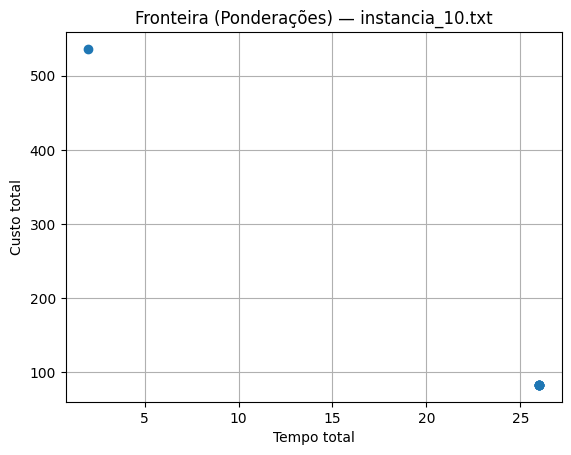

In [ ]:

# %% Salvando CSVs e gráficos simples de Pareto
import os
import matplotlib.pyplot as plt

saida = base.parent / "resultados_po2"
os.makedirs(saida, exist_ok=True)

for nome, df in resultados_ponderacoes.items():
    df.to_csv(saida / f"{Path(nome).stem}_ponderacoes.csv", index=False)

for nome, df in resultados_eps_teto_custo.items():
    df.to_csv(saida / f"{Path(nome).stem}_eps_teto_custo.csv", index=False)

for nome, df in resultados_eps_teto_tempo.items():
    df.to_csv(saida / f"{Path(nome).stem}_eps_teto_tempo.csv", index=False)

# Plot Pareto (tempo no eixo x, custo no eixo y) para uma instância de exemplo (ponderações)
exemplo_nome = list(resultados_ponderacoes.keys())[0] if resultados_ponderacoes else None
if exemplo_nome:
    df_ex = resultados_ponderacoes[exemplo_nome].dropna(subset=["tempo", "custo"])
    plt.figure()
    plt.scatter(df_ex["tempo"], df_ex["custo"])
    plt.xlabel("Tempo total")
    plt.ylabel("Custo total")
    plt.title(f"Fronteira (Ponderações) — {exemplo_nome}")
    plt.grid(True)
    plt.show()
